#### 数据预处理
原始数据的形式：每一行的顺序为：
单元号
时间，以周期为单位
操作设置1
操作设置2
操作设置3
传感器测量1
传感器测量2
...
传感器测量21
每个时间序列开始时，发动机处于正常运行状态，并在某个时间点出现故障。在训练集中的故障会随着时间推移逐渐加剧，直到系统失效。在测试集中的时间序列会在系统失效之前某个时刻结束。本次比赛的目标是预测在测试集中的剩余操作周期数，即从最后一个周期开始，发动机还能继续运行多少操作周期。同时，还提供了测试数据的真实剩余使用寿命（RUL）值的向量

**为每个数据添加列名标识，统计每个工况下的发动机寿命**

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from scipy.signal import savgol_filter  # 用于传感器噪声平滑

col_names = [
    'unit_number', 'time_in_cycles',  # 1-2：发动机ID、循环次数
    'op_setting_1', 'op_setting_2', 'op_setting_3',  # 3-5：3个操作条件
    'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5',  # 6-10：传感器1-5
    'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10',  # 11-15：传感器6-10
    'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15',  # 16-20：传感器11-15
    'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20',  # 21-25：传感器16-20
    'sensor_21'  # 26：传感器21
]

# 加载数据
train_data = pd.read_csv('CMAPSSData/train_FD001.txt', sep='\\s+', names=col_names)  # sep='\s+'处理任意空格
test_data = pd.read_csv('CMAPSSData/test_FD001.txt', sep='\\s+', names=col_names)
true_rul = pd.read_csv('CMAPSSData/RUL_FD001.txt', sep='\\s+', header=None, names=['true_rul'])  # 无表头，列名设为true_rul

# 验证数据格式（确保列数正确、发动机ID匹配）
print(f"训练集形状：{train_data.shape}")
print(f"测试集发动机数量：{test_data['unit_number'].nunique()}")
print(f"真实RUL数量：{len(true_rul)}")

# ==================================================================================
# 1. 计算训练集RUL
max_cycles_train = train_data.groupby('unit_number')['time_in_cycles'].max().reset_index()
max_cycles_train.columns = ['unit_number', 'max_cycle']
train_data = train_data.merge(max_cycles_train, on='unit_number')
train_data['rul'] = train_data['max_cycle'] - train_data['time_in_cycles']  # 训练集目标变量

# 2. 匹配测试集真实RUL（【核心修正2：按发动机ID顺序匹配，保留所有循环】）
max_cycles_test = test_data.groupby('unit_number')['time_in_cycles'].max().reset_index()
max_cycles_test.columns = ['unit_number', 'last_cycle']
test_data = test_data.merge(max_cycles_test, on='unit_number')
# 为测试集所有循环添加“真实RUL”（真实RUL是“最后一个循环到故障的次数”，故每个发动机的所有循环RUL=真实RUL + (最后一个循环 - 当前循环)）
test_data['true_rul'] = test_data.groupby('unit_number')['last_cycle'].transform(
    lambda x: true_rul.loc[x.name - 1, 'true_rul'] + (x.iloc[0] - test_data.loc[x.index, 'time_in_cycles'])
)

训练集形状：(20631, 26)
测试集发动机数量：100
真实RUL数量：100


#### 处理噪声与归一化
直接用原始传感器数据会影响 PCA 降维效果，噪声会被误认为 “有用信息”，这里使用Savitzky-Golay滤波，sklearn自带的算法

归一化则是因为不同的数据范围和尺度不一样

In [3]:
sensor_cols = [col for col in col_names if col.startswith('sensor_')]

# 对训练集和测试集的传感器数据进行平滑处理（窗口大小5，多项式阶数2，避免过平滑）
for col in sensor_cols:
    # 按发动机ID分组平滑（避免不同发动机的趋势混淆）
    train_data[col + '_smoothed'] = train_data.groupby('unit_number')[col].transform(
        lambda x: savgol_filter(x, window_length=5, polyorder=2, mode='nearest')
    )
    test_data[col + '_smoothed'] = test_data.groupby('unit_number')[col].transform(
        lambda x: savgol_filter(x, window_length=5, polyorder=2, mode='nearest')
    )

# 替换原始传感器列为平滑后的列（后续建模用平滑数据）

smoothed_sensor_cols = [col + '_smoothed' for col in sensor_cols]
train_data = train_data.drop(columns=sensor_cols).rename(columns=dict(zip(smoothed_sensor_cols, sensor_cols)))
test_data = test_data.drop(columns=sensor_cols).rename(columns=dict(zip(smoothed_sensor_cols, sensor_cols)))

# ======================================归一化=================
feature_cols = [col for col in col_names if col not in ['unit_number', 'time_in_cycles', 'op_setting_1', 'op_setting_2', 'op_setting_3']]  # 输入特征
static_features = [col for col in feature_cols if train_data[col].std() == 0]
print(f"删除的静态特征：{static_features}")
valid_features = [col for col in feature_cols if col not in static_features]

def normalize_by_initial_cycle(df, valid_features):
    # 获取每个发动机的初始循环数据
    initial_cycles = df[df['time_in_cycles'] == 1][['unit_number'] + valid_features].copy()
    initial_cycles.columns = ['unit_number'] + [f'{col}_initial' for col in valid_features]
    # 合并初始数据到原数据
    df_norm = df.merge(initial_cycles, on='unit_number')
    # 归一化：(当前值 - 初始值) / 初始值（相对变化率，更能反映退化趋势）
    for col in valid_features:
        df_norm[col + '_norm'] = (df_norm[col] - df_norm[f'{col}_initial']) / df_norm[f'{col}_initial']
    # 返回归一化后的特征列
    return df_norm, [f'{col}_norm' for col in valid_features]

# 对训练集和测试集进行个体归一化
train_data_norm, norm_features = normalize_by_initial_cycle(train_data, valid_features)
test_data_norm, _ = normalize_by_initial_cycle(test_data, valid_features)
test_data_last_norm = test_data_norm[test_data_norm['time_in_cycles'] == test_data_norm['last_cycle']].copy()

删除的静态特征：['sensor_10']


PCA方差解释率
原始有效特征数：20
PCA后主成分总数：7
最终累计方差解释率：0.9598（即保留了原始数据95.98%的信息）

各主成分详细方差解释率：
主成分编号 单个方差解释率 累计方差解释率
  PC1  0.6801  0.6801
  PC2  0.0625  0.7426
  PC3  0.0528  0.7954
  PC4  0.0464  0.8418
  PC5  0.0436  0.8853
  PC6  0.0376  0.9230
  PC7  0.0368  0.9598


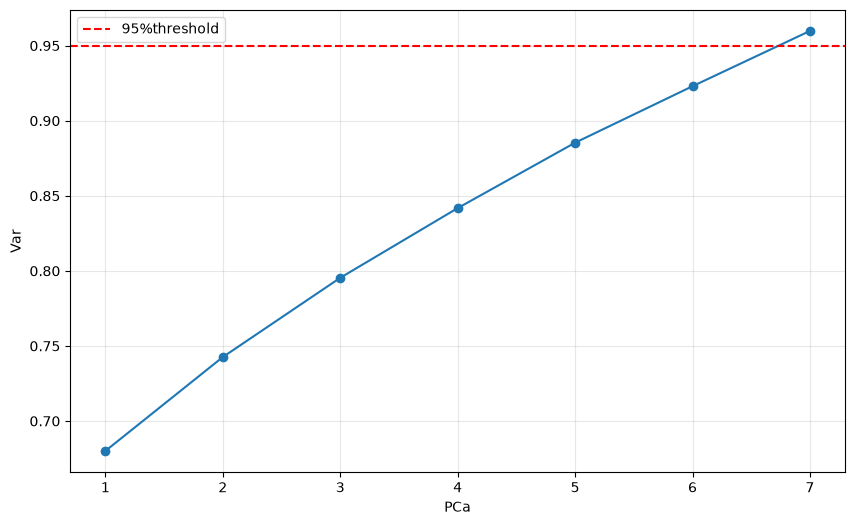

In [4]:
X_train = train_data_norm[norm_features]
y_train = train_data_norm['rul']
X_test = test_data_norm[norm_features]
y_test = test_data_norm['true_rul']
X_test_last = test_data_last_norm[norm_features]  # 测试集最后一个循环（用于最终评估）
y_test_last = test_data_last_norm['true_rul']

# ==============================降维====
# 初始化PCA（保留95%方差，避免噪声干扰）
pca = PCA(n_components=0.95, random_state=42)
# 训练集PCA降维（仅用训练集拟合，避免数据泄露）
X_train_pca = pca.fit_transform(X_train)
# 测试集PCA降维（用训练集的PCA模型转换）
X_test_pca = pca.transform(X_test)
X_test_last_pca = pca.transform(X_test_last)

# 提取单个主成分的方差解释率
single_variance_ratio = pca.explained_variance_ratio_  

# 计算累计方差解释率（对单个解释率做累加）
cumulative_variance_ratio = np.cumsum(single_variance_ratio) 

variance_df = pd.DataFrame({
    '主成分编号': [f'PC{i+1}' for i in range(len(single_variance_ratio))],
    '单个方差解释率': [f'{ratio:.4f}' for ratio in single_variance_ratio],  
    '累计方差解释率': [f'{cum_ratio:.4f}' for cum_ratio in cumulative_variance_ratio]
})

print("="*60)
print("PCA方差解释率")
print("="*60)
print(f"原始有效特征数：{len(valid_features)}")
print(f"PCA后主成分总数：{len(single_variance_ratio)}")
print(f"最终累计方差解释率：{cumulative_variance_ratio[-1]:.4f}（即保留了原始数据{cumulative_variance_ratio[-1]*100:.2f}%的信息）")
print("\n各主成分详细方差解释率：")
print(variance_df.to_string(index=False))  # 不显示DataFrame的索引，仅展示内容

# 可视化PCA方差解释率（碎石图）
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(pca.explained_variance_ratio_) + 1),
         np.cumsum(pca.explained_variance_ratio_),
         marker='o', linestyle='-', color='#1f77b4')
plt.xlabel('PCa')
plt.ylabel('Var')
plt.axhline(y=0.95, color='red', linestyle='--', label='95%threshold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('pca_variance_ratio.png', dpi=300, bbox_inches='tight')
plt.show()